In [67]:
import numpy as np
from sklearn.datasets import make_moons




In [68]:
from matplotlib import pyplot as plt


#hand craft knn
def knn_predict(X_train, y_train, X_test, k, distance_func):
    distances = distance_func(X_train, X_test)  #distance to all training points
    neighbors = np.argsort(distances)[:k]  # k-nn
    print(y_train[neighbors])
    y_pred = np.bincount(y_train[neighbors]).argmax()  #vote
    return y_pred


def acc(y_true, y_pred):
    return np.mean(y_true == y_pred)


def knn_error(x, y, k, distance_func):
    train_error = np.mean([knn_predict(x, y, point, k, distance_func) != label for point, label in zip(x, y)])
    test_error = np.mean(
        [knn_predict(np.delete(x, i, axis=0), np.delete(y, i), x[i], k, distance_func) != y[i] for i in range(len(y))])
    return train_error, test_error


def visualize_knn(x, y, k, distance_func, ):
    a = np.linspace(x[:, 0].min() - 0.1, x[:, 0].max() + 0.1, 100)
    b = np.linspace(x[:, 1].min() - 0.1, x[:, 1].max() + 0.1, 100)

    grid = np.array([[i, j] for i in a for j in b]) # collect nearby point and use its' prediction value to visualize knn prediction at different position.
    labels = [
        knn_predict(x, y, point, k, distance_func)
        for point in grid
    ]

    plt.figure()
    plt.scatter(grid[:, 0], grid[:, 1], c=labels,
                marker='s', s=12, alpha=0.25)
    plt.scatter(x[:, 0], x[:, 1], c=y)
    plt.show()


In [91]:
#perceptron and neoron
def train_perceptron(training_record, learning_rate, w1, w2, b):
    x1, x2, y = training_record
    predicted = 1 if w1 * x1 + w2 * x2 + b > 0 else -1
    if y * predicted <= 0:
        w1 += learning_rate * x1 * y  # w <- w + eta * y * x
        w2 += learning_rate * x2 * y
        b += learning_rate * y
    return w1, w2, b


def train_neuron(training_record, learning_rate, w, b, cost_derivative, activation_derivative, activation):
    x, y = training_record
    z = w * x + b
    y_pred = activation(z)
    gradient = cost_derivative(y_pred, y) * activation_derivative(z)

    w -= learning_rate * gradient * x # gradient descent
    b -= learning_rate * gradient
    return w, b, gradient * x, gradient





In [70]:
np.random.seed(42)
X, y = make_moons(n_samples=200, noise=0.15)

In [71]:
#test knn with differnent k and oder of norm
ps = [1, 2]
points = [(0.40, 0.45), (0.08, 0.78), (0.75, -0.15)]
ks = [1, 3, 5]
for point in points:
    for p in ps:
        for k in ks:
            print(
                f'point = {point}, p = {p}, k = {k}, prediction = {knn_predict(X, y, point, k, lambda x1, x2: np.linalg.norm(x1 - x2, ord=p, axis=1))}')

[0]
point = (0.4, 0.45), p = 1, k = 1, prediction = 0
[0 1 1]
point = (0.4, 0.45), p = 1, k = 3, prediction = 1
[0 1 1 1 1]
point = (0.4, 0.45), p = 1, k = 5, prediction = 1
[0]
point = (0.4, 0.45), p = 2, k = 1, prediction = 0
[0 1 1]
point = (0.4, 0.45), p = 2, k = 3, prediction = 1
[0 1 1 1 1]
point = (0.4, 0.45), p = 2, k = 5, prediction = 1
[1]
point = (0.08, 0.78), p = 1, k = 1, prediction = 1
[1 0 0]
point = (0.08, 0.78), p = 1, k = 3, prediction = 0
[1 0 0 0 0]
point = (0.08, 0.78), p = 1, k = 5, prediction = 0
[1]
point = (0.08, 0.78), p = 2, k = 1, prediction = 1
[1 0 0]
point = (0.08, 0.78), p = 2, k = 3, prediction = 0
[1 0 0 0 0]
point = (0.08, 0.78), p = 2, k = 5, prediction = 0
[1]
point = (0.75, -0.15), p = 1, k = 1, prediction = 1
[1 0 1]
point = (0.75, -0.15), p = 1, k = 3, prediction = 1
[1 0 1 0 1]
point = (0.75, -0.15), p = 1, k = 5, prediction = 1
[0]
point = (0.75, -0.15), p = 2, k = 1, prediction = 0
[0 1 1]
point = (0.75, -0.15), p = 2, k = 3, prediction = 1
[0

[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]
[0]


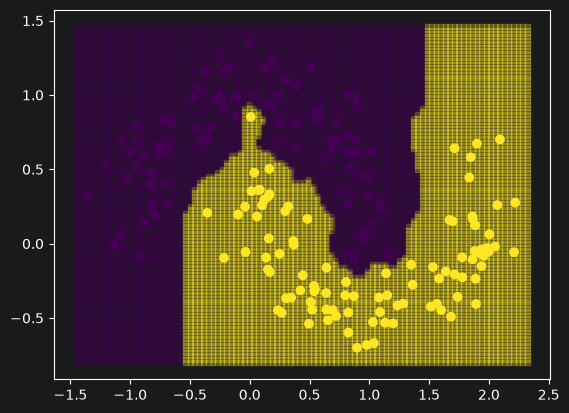

[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0 0 0 0 0 0]
[0 0 0 0 0

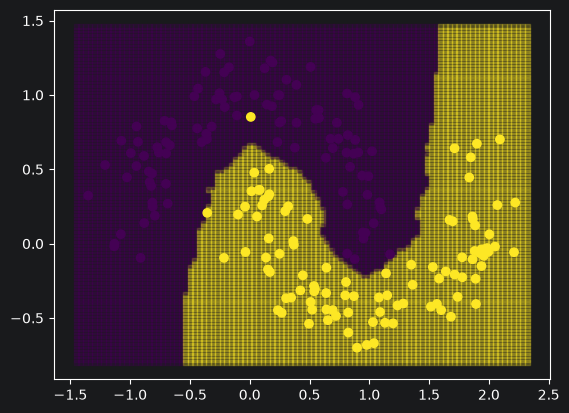

In [72]:
# 1nn vs 10nn
visualize_knn(X, y, 1, lambda x1, x2: np.linalg.norm(x1 - x2, ord=1, axis=1))
visualize_knn(X, y, 10, lambda x1, x2: np.linalg.norm(x1 - x2, ord=1, axis=1))

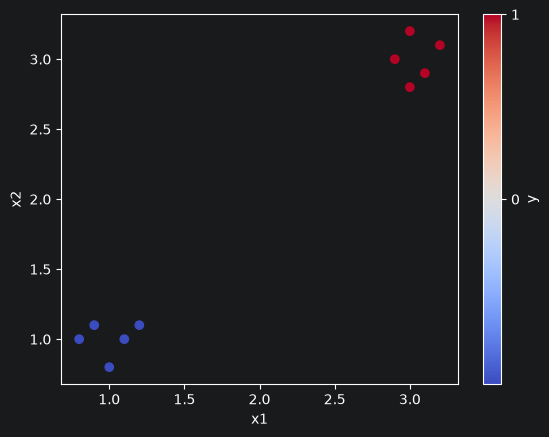

In [73]:
points_neuron = np.array([(0.9, 1.1, -1), (1.0, 0.8, -1), (1.1, 1.0, -1), (0.8, 1.0, -1), (1.2, 1.1,
                                                                                           -1), (3.1, 2.9, 1),
                          (3.0, 3.2, 1), (2.9, 3.0, 1), (3.2, 3.1, 1), (3.0, 2.8, 1)])
plt.scatter(points_neuron[:, 0], points_neuron[:, 1],
            c=points_neuron[:, 2], cmap='coolwarm')
plt.xlabel('x1')
plt.ylabel('x2')
plt.colorbar(ticks=[0, 1], label='y')
plt.show()


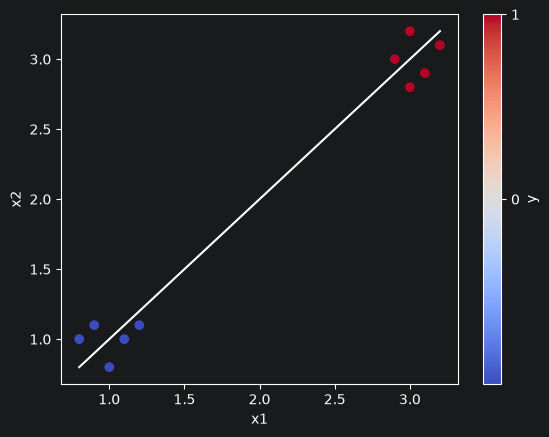

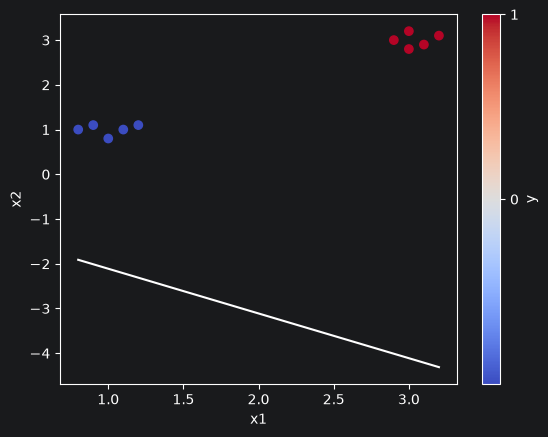

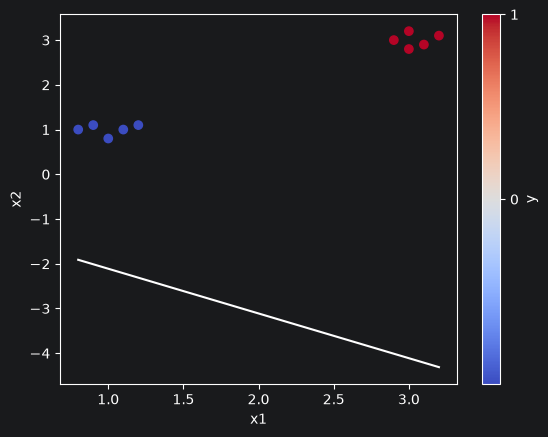

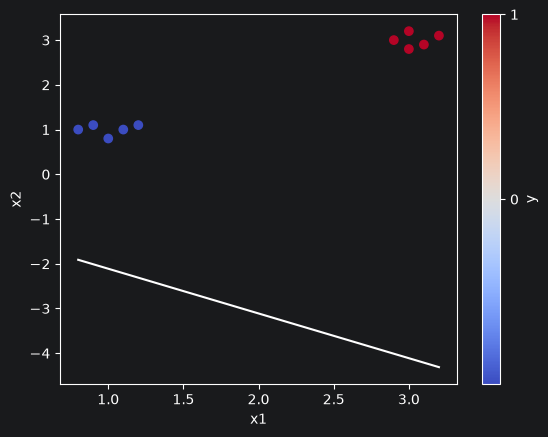

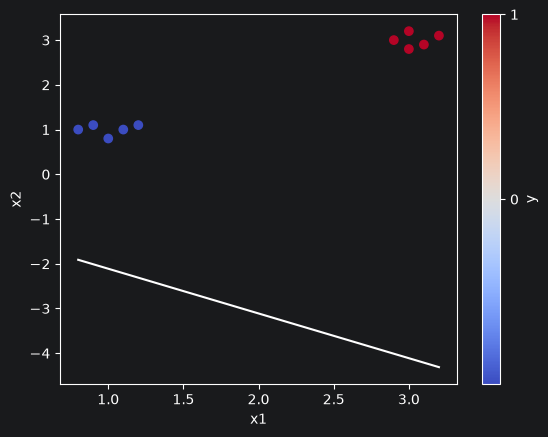

...

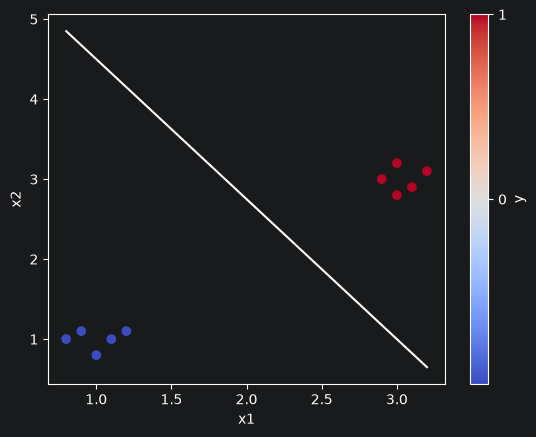

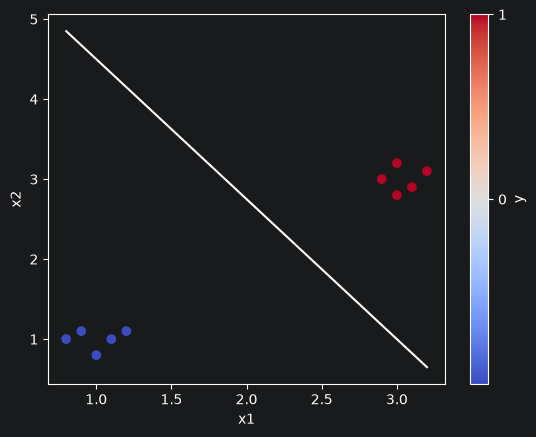

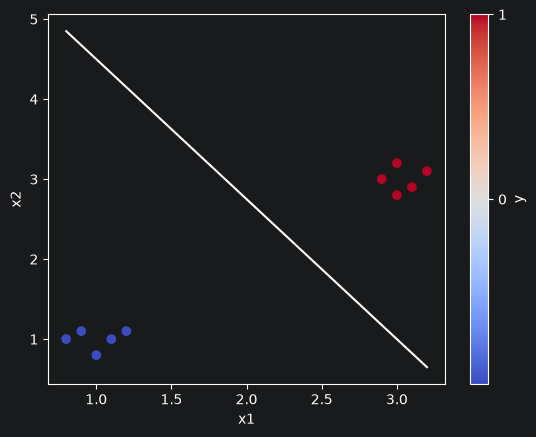

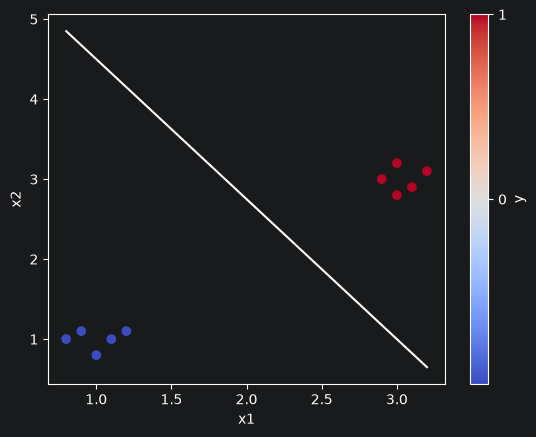

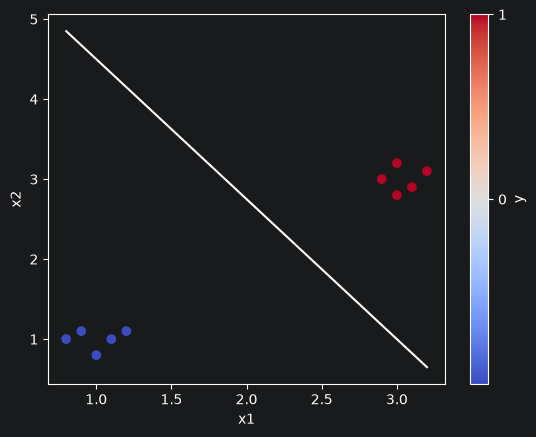

In [85]:
w1, w2, b = 0.1, 0.1, 0.1


ws = set()

# complete train process.
def test_perceptron(data, w1, w2, b):
    flag = False
    while 1 == 1:
        unchanged = 0
        w1p, w2p, bp = w1, w2, b
        for i in range(len(data)):
            w1, w2, b = train_perceptron(data[i], 0.1, w1, w2, b)
            if w1 == w1p and w2 == w2p and b == bp: # if the weight and bias are unchanged no need to visualize
                unchanged += 1

                w1p, w2p, bp = w1, w2, b
                # print(w1, w2, b)
                # print(unchanged, len(data))
                if unchanged == len(data):
                    flag = True
                    break
            else:
                unchanged = 0
                plt.scatter(data[:, 0], data[:, 1],
                            c=data[:, 2], cmap='coolwarm')

                x1 = np.linspace(data[:, 0].min(), data[:, 0].max(), 100)
                x2 = -(w1 * x1 + b) / w2
                plt.plot(x1, x2, color='white')
                plt.xlabel('x1')
                plt.ylabel('x2')
                plt.colorbar(ticks=[0, 1], label='y')
                plt.show()
                # if (w1, w2, b) not in ws:
                #     ws.add((w1, w2, b))
                # else:
                #     flag = True
                #     break
        if flag:
            break


test_perceptron(points_neuron, w1, w2, b)







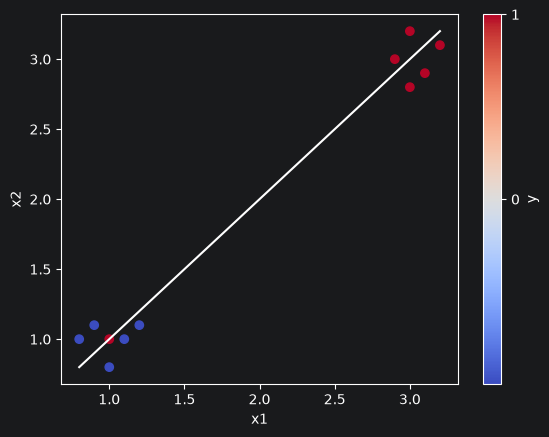

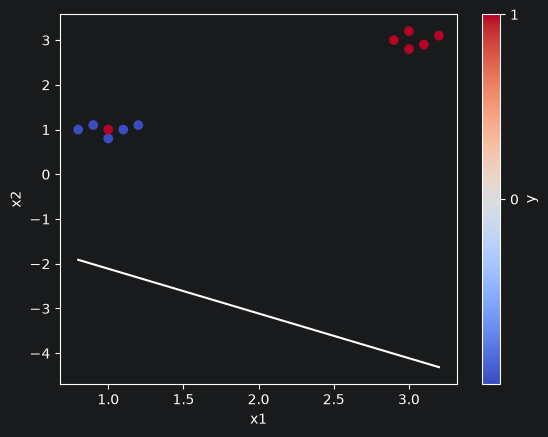

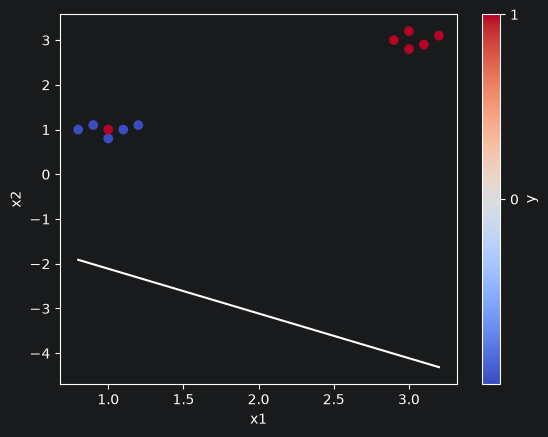

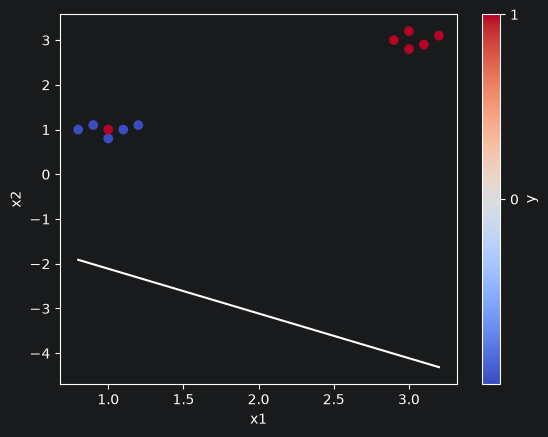

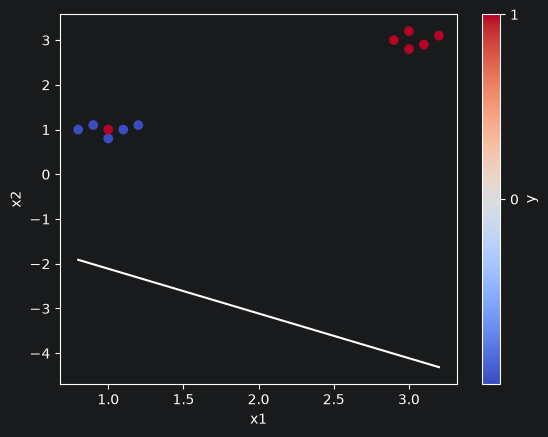

...

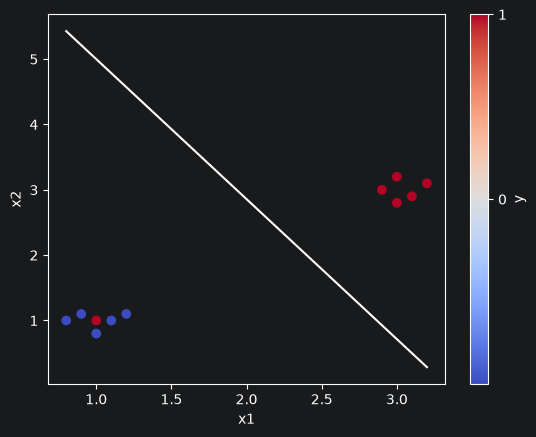

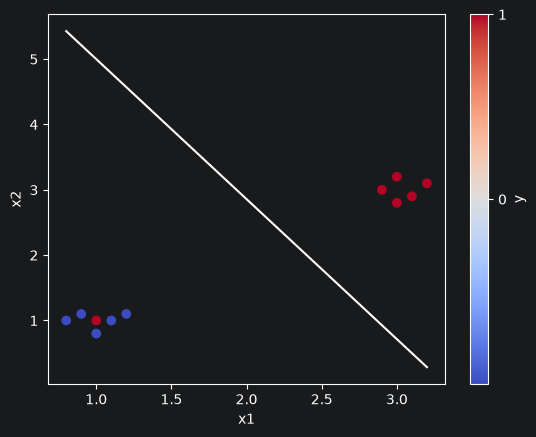

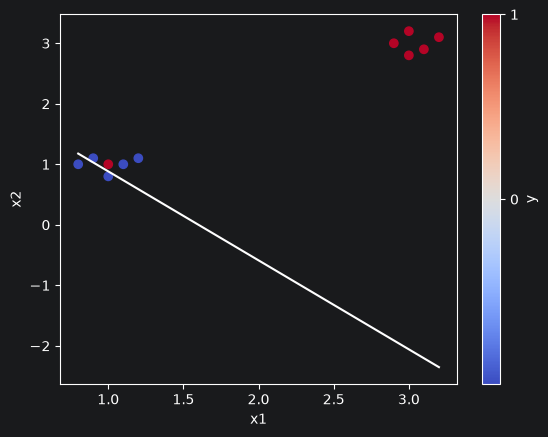

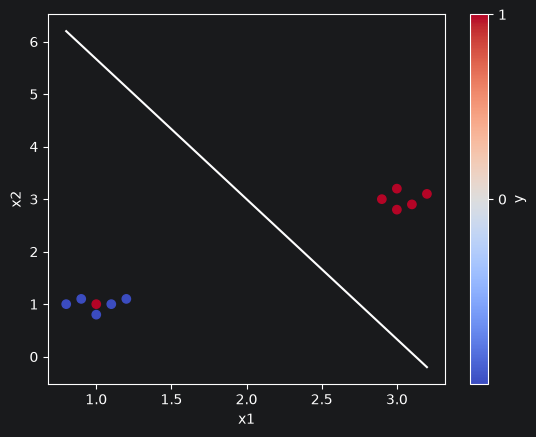

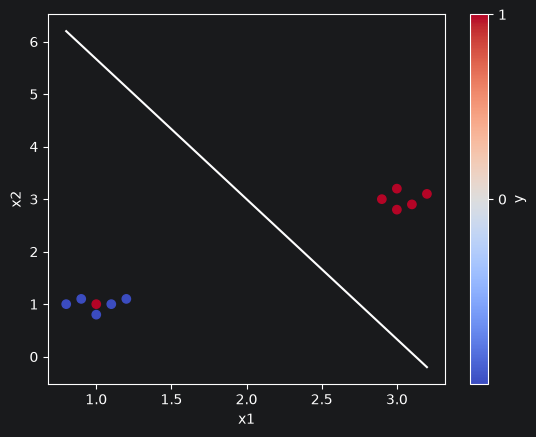

KeyboardInterrupt: 

In [86]:
points_neuron_two = np.array([(0.9, 1.1, -1), (1.0, 0.8, -1), (1.1, 1.0, -1), (0.8, 1.0, -1), (1.2, 1.1,
                                                                                               -1), (3.1, 2.9, 1),
                              (3.0, 3.2, 1), (2.9, 3.0, 1), (3.2, 3.1, 1), (3.0, 2.8, 1), (1, 1, 1)])
w1, w2, b = 0.1, 0.1, 0.1

# non linearly seperable so it never ends
test_perceptron(points_neuron_two, w1, w2, b)


In [76]:
from random import uniform


def generate_noisy_dataset(functions, f, x_range, n_samples, noise):
    res = []
    for _ in range(n_samples):
        x = uniform(*x_range)
        res.append([x] + [g(x) for g in functions] + [f(x) + uniform(-noise, noise)])
    return res

In [77]:
data = generate_noisy_dataset([lambda x: 2 * x + 3], lambda x: 0, (0, 1), 100, 0.1)

In [78]:
print(data)

[[0.48298996113151205, 3.965979922263024, -0.04584006795440612], [0.36030656062537314, 3.7206131212507465, -0.08762052336836045], [0.524101913407924, 4.048203826815848, -0.09166962393969645], [0.360951736380304, 3.7219034727606077, -0.09495375716872556], [0.1516001972681943, 3.303200394536389, -0.0793928305262627], [0.11726734113582893, 3.234534682271658, -0.04469270865457689], [0.23023586872357782, 3.460471737447156, -0.006269720411652219], [0.41831280574829843, 3.836625611496597, -0.053454669429107086], [0.9754556993296194, 4.950911398659239, 0.011179816761882816], [0.6750342816144601, 4.35006856322892, 0.0008007357503379414], [0.39474380878814286, 3.7894876175762855, 0.049462790560807435], [0.34690688834653405, 3.693813776693068, -0.047093565915004555], [0.09656714533690014, 3.1931342906738003, 0.06094286438969038], [0.044149373544626114, 3.0882987470892522, 0.084424884712897], [0.7445059789382859, 4.4890119578765715, 0.04553251693608576], [0.8160286370114758, 4.6320572740229515, 0.

In [82]:
# plot the neuron training process.
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

data = np.array(generate_noisy_dataset([], lambda x: 2 * x + 3, (0, 1), 100, 0.1))
activations = {
    'sigmoid': (lambda z: 1 / (1 + np.exp(-z)), lambda z: np.exp(-z) / (1 + np.exp(-z)) ** 2),
    'tanh': (np.tanh, lambda z: 1 - np.tanh(z) ** 2),
    'relu': (lambda z: np.maximum(0, z), lambda z: float(z > 0))
}
cost_derivative = lambda y_pred, y: 2 * (y_pred - y)
x = np.linspace(0, 1, 100)

lrs = [0.001, 0.01, 0.1, 1, 10]

for name, (activation, activation_derivative) in activations.items():
    for lr in lrs:
        w, b = 0.1, 0.1
        print(f'lr {lr}')
        runs = [(w, b)]
        for record in data:
            w, b, _, _ = train_neuron(record, lr, w, b, cost_derivative, activation_derivative, activation)
            runs.append((w, b))

        fig, ax = plt.subplots()
        ax.scatter(data[:, 0], data[:, 1], label='training data')
        ax.plot(x, 2 * x + 3, color='red', label='true function')
        line, = ax.plot(x, activation(0.1 * x + 0.1), color='orange', label='model')
        ax.set(xlabel='x', ylabel='y', ylim=(-1.2, 5.5))
        ax.legend()


        def update(i):
            w, b = runs[i]
            line.set_ydata(activation(w * x + b))
            ax.set_title(f'{name}, squared error, update {i}')


        ani = FuncAnimation(fig, update, frames=len(runs))
        plt.close(fig)
        display(HTML(ani.to_jshtml()))



lr 0.001


lr 0.01


lr 0.1


lr 1


lr 10


lr 0.001


lr 0.01


lr 0.1


lr 1


lr 10


lr 0.001


lr 0.01


lr 0.1


lr 1


lr 10


lr 0.001


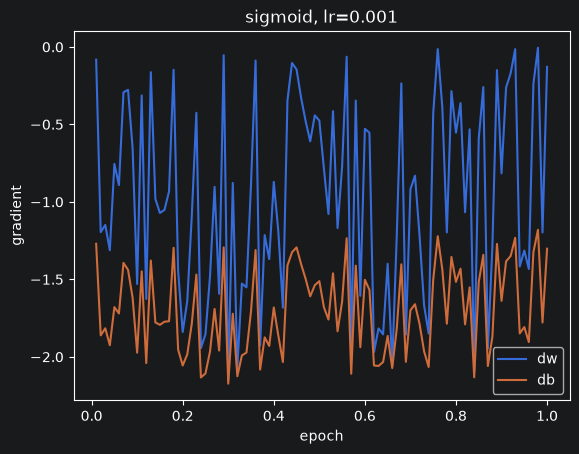

lr 0.01


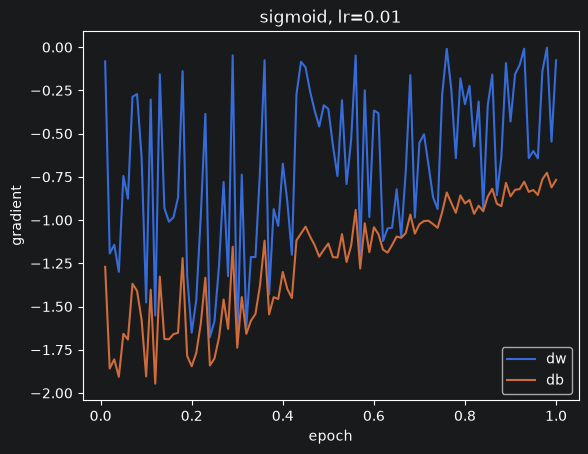

lr 0.1


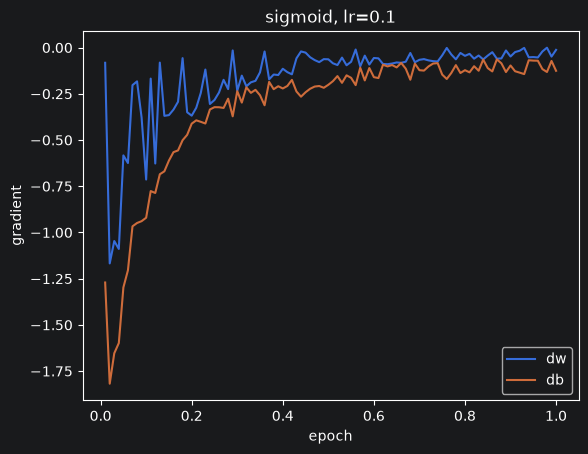

lr 1


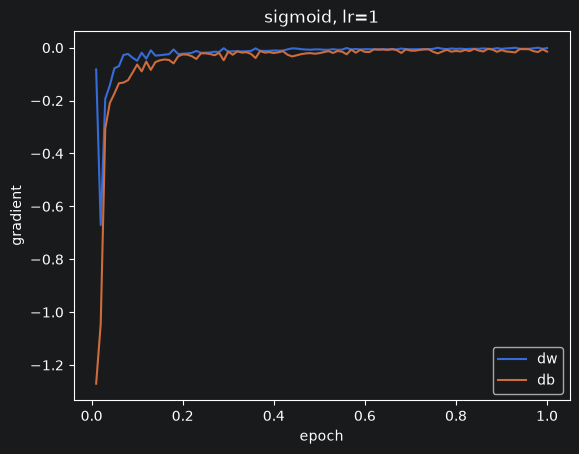

lr 10


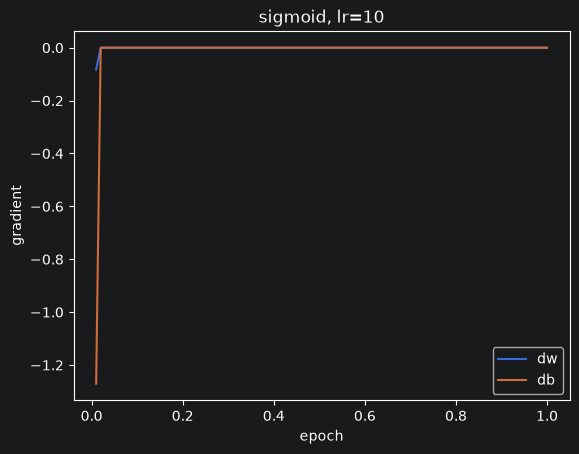

lr 0.001


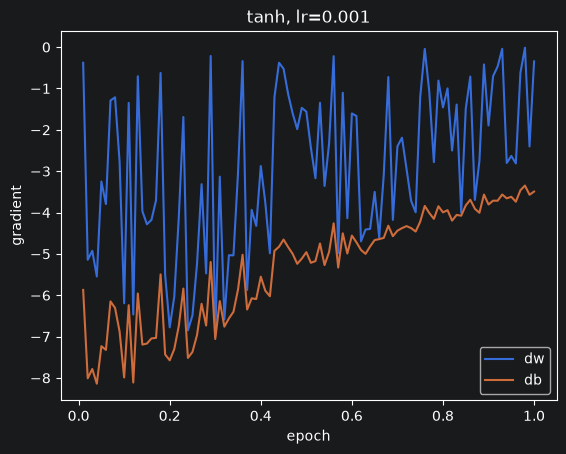

lr 0.01


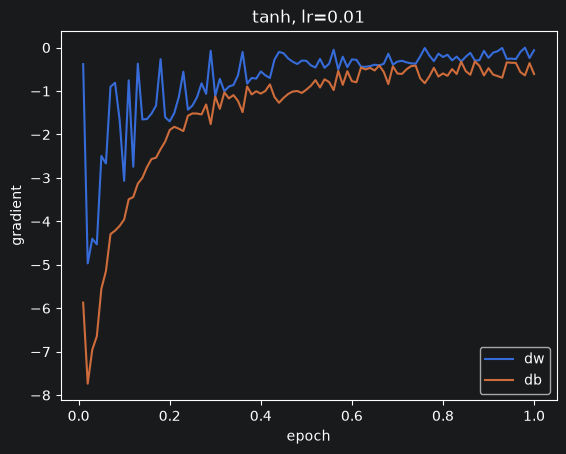

lr 0.1


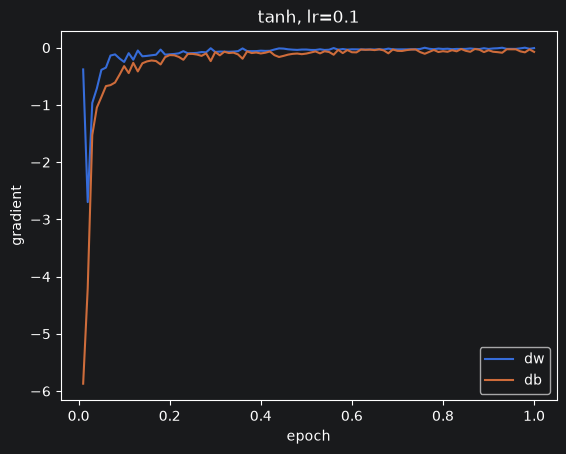

lr 1


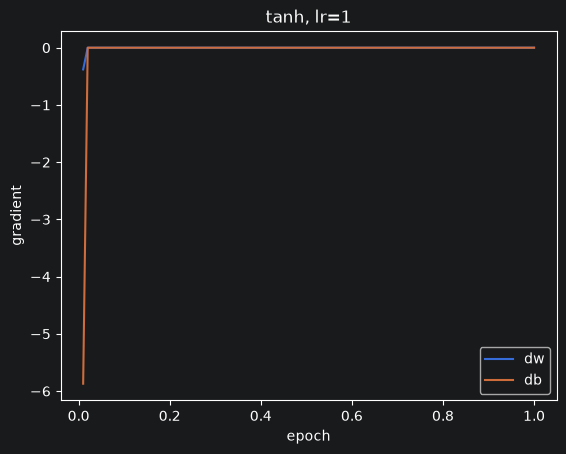

lr 10


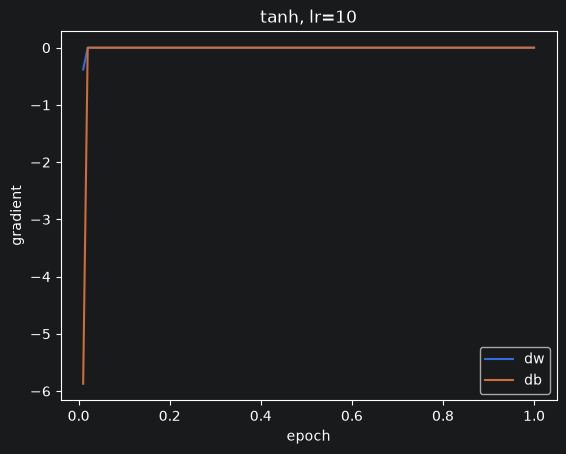

lr 0.001


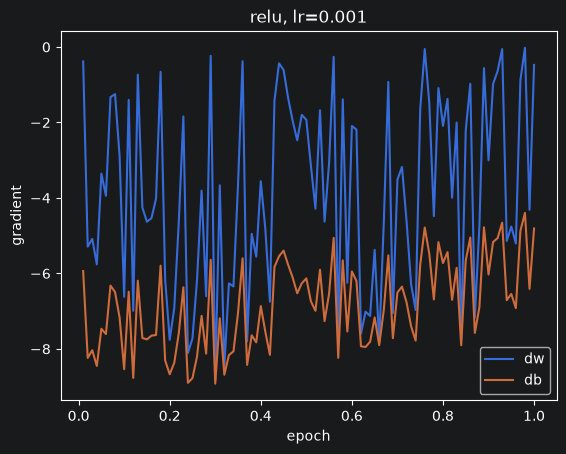

lr 0.01


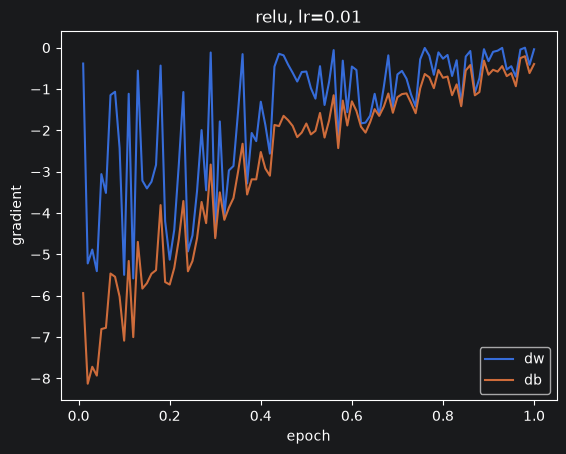

lr 0.1


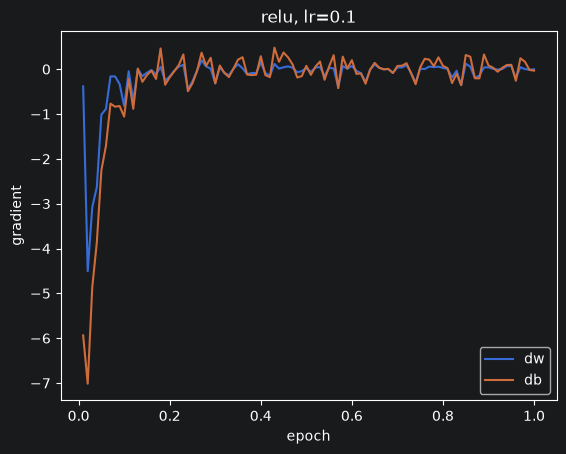

lr 1


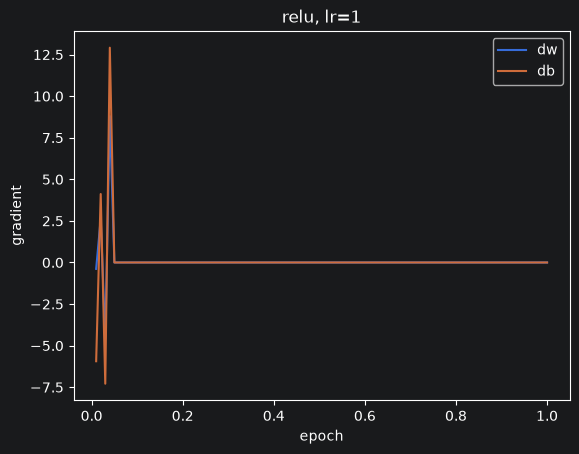

lr 10


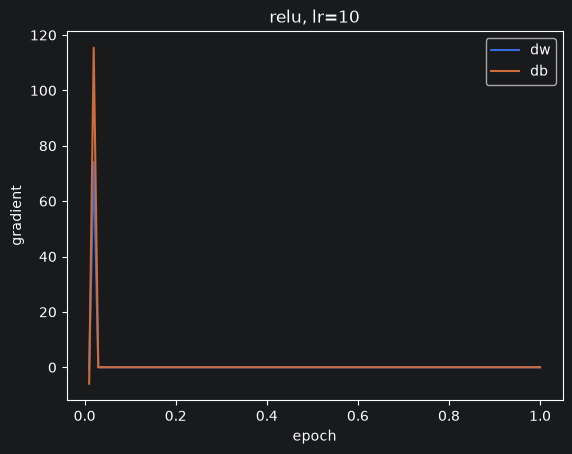

In [92]:
#visualise gradient changes for different combination of hyper-parameters.
for name, (activation, activation_derivative) in activations.items():
    for lr in lrs:
        w, b = 0.1, 0.1
        print(f'lr {lr}')
        runs, gradients = [(w, b)], []

        for record in data:
            w, b, dw, db = train_neuron(record, lr, w, b, cost_derivative, activation_derivative, activation)
            runs.append((w, b))
            gradients.append((dw, db))

        epochs = np.arange(1, len(gradients) + 1) / len(data)

        gradients = np.array(gradients)
        plt.figure()
        plt.plot(epochs, gradients[:, 0], label='dw')
        plt.plot(epochs, gradients[:, 1], label='db')
        plt.xlabel('epoch')
        plt.ylabel('gradient')
        plt.title(f'{name}, lr={lr}')
        plt.legend()
        plt.show()